# Connect Suggests: data and models

**Fonecta challenge, Since AI Hackathon 2026.** This notebook is the evidence behind the score engine in `cs/engine/`.
Every model here is the same code the app imports (`cs.engine.*`); the notebook only calls it and shows the results.

**The task in one line.** For 3,000 businesses and every special day from 7 Nov 2026 to 6 Jan 2027, decide whether the
hours Google shows are wrong, and if so suggest the right hours (`SUGGEST`), stay quiet (`NO_ACTION`), or send the
case to a person (`FLAG`). The official scorer gives +1 for exact hours and −1 for getting open/closed backwards.

**How to read it.** Each step starts with *what* we do and *why*, then the code and output, then *what it means for the
design*. Heavy steps (cross-validation) are cached in `artifacts/cache/` by `scripts/train.py` and
`scripts/eval_ablations.py`; the notebook reads the caches and recomputes them only if they are missing.

| Model | What it does | Section |
|---|---|---|
| M1 | Habit-type mixture (EM): links a business's days together | 7 |
| M2 | State model: closed / regular / special per business and date | 9 |
| M3 | Hours ranker + isotonic calibration: which exact hours | 10 |
| M4 | Decision rule: expected points under the scorer's table, flip margin λ | 11 |
| M5 | Closed-for-good scorer | 12 |

In [1]:
import sys, json, subprocess, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cs.engine import data as D, features as F, habits as H, pipeline as P, decide as DC, flags as FL
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 3)
CACHE = D.CACHE; CACHE.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
INK, ACCENT, MUTED = "#1f2937", "#2563eb", "#9ca3af"
t_start = time.time()
NBM = {}  # key numbers, used to fill the narrative

## 1. Data overview and quality checks

**What.** Load every file through `cs/engine/data.py` and check sizes, splits, entry sources and timing, and that our
"what Google shows now" logic reproduces Fonecta's `displayed_hours_at_snapshot`.

**Why.** Everything later depends on two things being right: which hours are shown today, and which data existed on
the snapshot date.

In [2]:
ents = D.entities()
print(f"{len(ents):,} entities ({(ents.role == 'SHOPPING_CENTRE').sum()} shopping centres), "
      f"{ents.segment.nunique() - 1} business types, {ents.city.nunique()} cities")
display(ents.groupby(["split", "country"]).size().unstack(fill_value=0))
h = D.holiday_history()
lead = (pd.to_datetime(h.date) - pd.to_datetime(h.entered_at)).dt.total_seconds() / 86400
print(f"\n{len(h):,} holiday-hour entries, {h.entity_id.nunique():,} businesses; dates {h.date.min()} .. {h.date.max()}")
display(pd.DataFrame({"entries": h.groupby("source").size(), "median_days_ahead": lead.groupby(h.source).median().round(1),
                      "share_entered_on_or_after_the_day": (lead <= 0).groupby(h.source).mean().round(3)}))
th = D.truth_history()
print(f"dev truth history: {len(th):,} rows, {th.entity_id.nunique()} dev businesses, {th.date.min()} .. {th.date.max()}")

3,032 entities (15 shopping centres), 33 business types, 28 cities


country,FI,NO,SE
split,,,
demo,13,2,2
dev,479,111,212
reference,8,3,4
test,1321,289,588



58,167 holiday-hour entries, 2,970 businesses; dates 2023-12-06 .. 2027-01-06


,entries,median_days_ahead,share_entered_on_or_after_the_day
source,,,
API_INTEGRATION,857,58.4,0.000
CONNECT_SUGGESTION,1329,20.5,0.000
FONECTA_SUPPORT,2544,7.3,0.067
OWNER_UI,53437,7.4,0.074


dev truth history: 58,711 rows, 802 dev businesses, 2024-01-01 .. 2026-11-05


In [3]:
# Quality checks
dups = h.duplicated(["entity_id", "date"], keep=False).sum()
bad = (~h.hours.str.match(r"^(REGULAR|closed|\d{2}:\d{2}-\d{2}:\d{2}(,\d{2}:\d{2}-\d{2}:\d{2})*)$")).sum()
print(f"entries with several rows for one date (later row wins): {dups}; malformed hours strings: {bad}")
for s in (2026, 2025):
    lab = D.labels(s)
    shown = D.displayed(lab, D.SNAP[s])
    print(f"{s}: our 'what Google shows now' matches displayed_hours_at_snapshot on "
          f"{(shown.values == lab.displayed_hours_at_snapshot.values).mean():.2%} of {len(lab):,} dev rows")
tg = D.targets(2026)
print("\n2026 target rows by split:", tg.split.value_counts().to_dict())

entries with several rows for one date (later row wins): 18; malformed hours strings: 0


2026: our 'what Google shows now' matches displayed_hours_at_snapshot on 100.00% of 11,100 dev rows
2025: our 'what Google shows now' matches displayed_hours_at_snapshot on 100.00% of 11,118 dev rows

2026 target rows by split: {'test': 30398, 'dev': 11100, 'demo': 257}


**Result.** The data is clean: no malformed hours, only a handful of re-entered dates, and our display logic (it
delegates to the builder's `cs/display.py`) reproduces Fonecta's shown hours on 100% of dev rows for both seasons.
Owners enter exceptions late: half of all entries come a week or less before the day, and some only on or after the day.

**For the design.** On the 6 Nov snapshot almost nothing is entered yet for December, so the engine must predict from
*last season's* behaviour, not from this season's entries. Late entries also mean the "already entered" signal is rare.

## 2. Label structure: where the needed changes are

**What.** Count, on dev 2026, which rows need a change (`expected_action`), by day and by mismatch type.

**Why.** The scorer divides points by the rows that need a change or a flag, so the big days and the dominant mistake
type decide the score.

{'NO_ACTION': 5702, 'SUGGEST': 5376, 'FLAG': 22}


mismatch_type,DIFFERENT_HOURS,SHOWN_CLOSED_ACTUALLY_OPEN,SHOWN_OPEN_ACTUALLY_CLOSED,no change needed,needs change %
day_key,,,,,
XMAS_DAY,97,0,631,74,91.0
NEW_YEARS_DAY,106,0,613,83,90.0
XMAS_EVE,251,0,471,80,90.0
EPIPHANY,147,0,378,166,76.0
NYE,344,0,189,269,66.0
SCHOOL_BREAK,43,0,0,27,61.0
BOXING_DAY,139,2,291,370,54.0
EPIPHANY_EVE,223,0,152,316,54.0
INTERDAY,179,3,602,1622,33.0


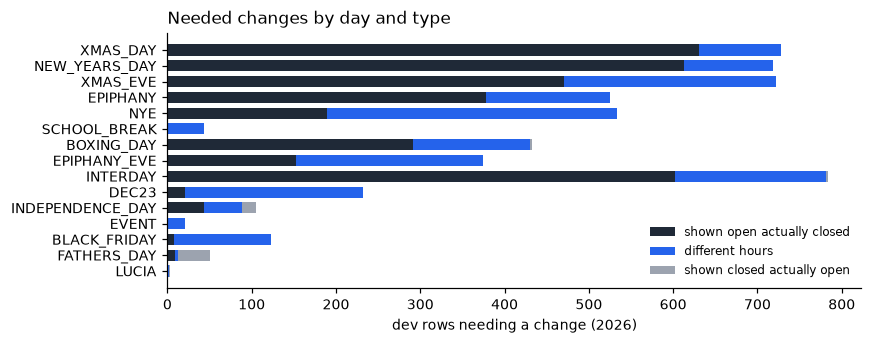

{'SHOWN_OPEN_ACTUALLY_CLOSED': 63.1, 'DIFFERENT_HOURS': 35.8, 'SHOWN_CLOSED_ACTUALLY_OPEN': 1.1}


In [4]:
lab = D.labels(2026)
print(lab.expected_action.value_counts().to_dict())
tab = pd.crosstab(lab.day_key, lab.mismatch_type.fillna("no change needed"))
tab["needs change %"] = (100 * (lab.expected_action != "NO_ACTION").groupby(lab.day_key).mean()).round(0)
tab = tab.sort_values("needs change %", ascending=False)
display(tab)
fig, ax = plt.subplots(figsize=(8, 3.2))
cols = ["SHOWN_OPEN_ACTUALLY_CLOSED", "DIFFERENT_HOURS", "SHOWN_CLOSED_ACTUALLY_OPEN"]
colors = [INK, ACCENT, MUTED]
left = np.zeros(len(tab))
for c_, col in zip(cols, colors):
    v = tab[c_].values if c_ in tab else np.zeros(len(tab))
    ax.barh(tab.index, v, left=left, color=col, label=c_.replace("_", " ").lower(), height=0.7)
    left += v
ax.invert_yaxis(); ax.set_xlabel("dev rows needing a change (2026)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Needed changes by day and type", loc="left"); plt.tight_layout(); plt.show()
print((lab[lab.expected_action == "SUGGEST"].mismatch_type.value_counts(normalize=True) * 100).round(1).to_dict())

**Result.** 5,376 of 11,100 dev rows need a change (plus 22 rows of two businesses that closed for good). 63% of the
needed changes are "shown open, actually closed"; 36% are different opening hours; only 1% are "shown closed,
actually open". Christmas, New Year's Day, Epiphany and New Year's Eve need a change for most businesses, while
Father's Day, Lucia and Black Friday rarely do.

**For the design.** Closed doors are the main harm, and the main prize: the engine must be good at predicting
*closed* on the big holidays, and careful about suggesting "closed" when the business is in fact open (that costs −1).

## 3. Leakage audit: what carries information from after the snapshot

**What.** For each file, find what is stamped after the snapshot (6 Nov 2026, or 6 Nov 2025 for the back-test) and
how we keep it out.

**Why.** A back-test that peeks at the future reports a score nobody will get on the hidden test.

In [5]:
s25 = D.SNAP[2025]
h25 = h[(h.date >= "2025-11-07") & (h.date <= "2026-01-06")]
pl = D.pilot_log()
pb = pd.read_csv(D.DS / "data" / "peer_benchmarks.csv")
A = D.analytics()
ue = D.user_edits(); R = D.reviews()
rows = [
    ("holiday_hours_history.jsonl", f"{(h25.entered_at >= s25).mean():.0%} of 2025-season entries were entered after 6 Nov 2025",
     "entries_as_of(as_of): strictly entered_at < as_of"),
    ("holiday_hours_history.jsonl (CONNECT_SUGGESTION)", f"{(h.source == 'CONNECT_SUGGESTION').sum()} entries are the 2025 pilot's accepted/edited suggestions",
     "counted as entries only once entered (before as_of); removable for the learning ablation"),
    ("pilot_decision_log_2025.csv", f"{(pl.sent_at >= s25).mean():.0%} of pilot messages were sent after 6 Nov 2025",
     "not used as a feature for the 2025 back-test"),
    ("peer_benchmarks.csv", f"pools seasons 2023-2025 ({len(pb):,} cells)", "not used: peers recomputed from entries before as_of"),
    ("regular_hours_history.jsonl", "versions effective after the snapshot", "effective_from <= as_of (cs.display)"),
    ("entities.json", "closed flag, reopenDate and current hours are the 2026 state", "used only when as_of >= 2026 snapshot"),
    ("reviews.json", f"{(R.ts >= pd.Timestamp(s25)).mean():.0%} of reviews are after 6 Nov 2025", "publisherDate < as_of"),
    ("publisher_suggestions.json", f"{(ue.created >= s25).mean():.0%} of user edits are after 6 Nov 2025", "dateCreated < as_of"),
    ("analytics_daily.parquet", f"runs to {A.date.max()}", "date < as_of (M5 only)"),
    ("labels/dev_truth_history.csv", "true hours up to 5 Nov 2026", "training only: periods ending before the target snapshot"),
]
display(pd.DataFrame(rows, columns=["file", "what is after the snapshot", "how we avoid it"]))

,file,what is after the snapshot,how we avoid it
0,holiday_hours_history.jsonl,97% of 2025-season entries were entered after ...,entries_as_of(as_of): strictly entered_at < as_of
1,holiday_hours_history.jsonl (CONNECT_SUGGESTION),1329 entries are the 2025 pilot's accepted/edi...,counted as entries only once entered (before a...
2,pilot_decision_log_2025.csv,100% of pilot messages were sent after 6 Nov 2025,not used as a feature for the 2025 back-test
3,peer_benchmarks.csv,"pools seasons 2023-2025 (7,114 cells)",not used: peers recomputed from entries before...
4,regular_hours_history.jsonl,versions effective after the snapshot,effective_from <= as_of (cs.display)
5,entities.json,"closed flag, reopenDate and current hours are ...",used only when as_of >= 2026 snapshot
6,reviews.json,30% of reviews are after 6 Nov 2025,publisherDate < as_of
7,publisher_suggestions.json,37% of user edits are after 6 Nov 2025,dateCreated < as_of
8,analytics_daily.parquet,runs to 2026-11-03,date < as_of (M5 only)
9,labels/dev_truth_history.csv,true hours up to 5 Nov 2026,training only: periods ending before the targe...


**Result.** The biggest trap is the entry history: about 97% of the 2025-season entries were made *after* 6 Nov 2025,
so a back-test that reads the file without the `entered_at` filter would look almost perfect. The provided
`peer_benchmarks.csv` pools 2023–2025, so it contains the 2025 answers; we never read it and compute peer statistics
ourselves from entries before the snapshot. `entities.json` shows today's state, so it is only used for 2026.

**For the design.** Every feature goes through `features.make_context(as_of)`, which filters each file by its own
timestamp. `tests/engine/test_engine.py` proves it: deleting all data stamped after the snapshot leaves the features
unchanged.

## 4. Label bias: owner entries versus the truth

**What.** Compare owner entries with the dev truth on the same days, and measure how often an entry exists depending
on what the business really did.

**Why.** If entries were a random sample of days, we could train on them directly. If owners mostly enter a day when
it is special, a model trained on entries learns a biased picture.

In [6]:
th = D.truth_history()
obs = H.truth_observations(th)
last = h.drop_duplicates(["entity_id", "date"], keep="last")
last = last[last.entered_at < last.date]
m = th.merge(last[["entity_id", "date", "hours"]], on=["entity_id", "date"], how="left").merge(
    obs[["entity_id", "date", "state"]], on=["entity_id", "date"], how="left")
has = m.hours.notna()
eh = np.where(m.hours == "REGULAR", m.displayed_hours_that_day, m.hours)
print(f"days with an owner entry: {has.sum():,} of {len(m):,}; the entry equals the truth on {(eh[has] == m.truth_hours[has]).mean():.1%}")
bias = m.groupby("state").apply(lambda g: g.hours.notna().mean()).rename("P(entry exists | true state)")
display(bias.to_frame().style.format("{:.1%}"))

days with an owner entry: 12,751 of 58,711; the entry equals the truth on 99.1%


,P(entry exists | true state)
state,
closed,28.6%
regular,2.1%
special,39.0%


**Result.** Entries are almost always right (99%), but they are **missing not at random**: a day that is really special
or closed has an entry 29–39% of the time, a day with regular hours only 2% of the time. The absence of an entry is
therefore weak evidence of "regular", and the days with entries are a biased sample.

**For the design.** We use entries as *features* and as *candidate hours*, but train the open/closed/special state
model (M2) and the habit types (M1) on the **unbiased dev truth**. In M1, an entry counts as an observation of that
day, and a missing entry counts as nothing.

## 5. Linked holidays

**What.** For each dev business and season, mark whether it was truly closed on each winter day, and correlate those
indicators across days.

**Why.** If closing on one holiday predicts closing on another, a business's known days tell us about its unknown
days, which is what "copy last year" cannot do.

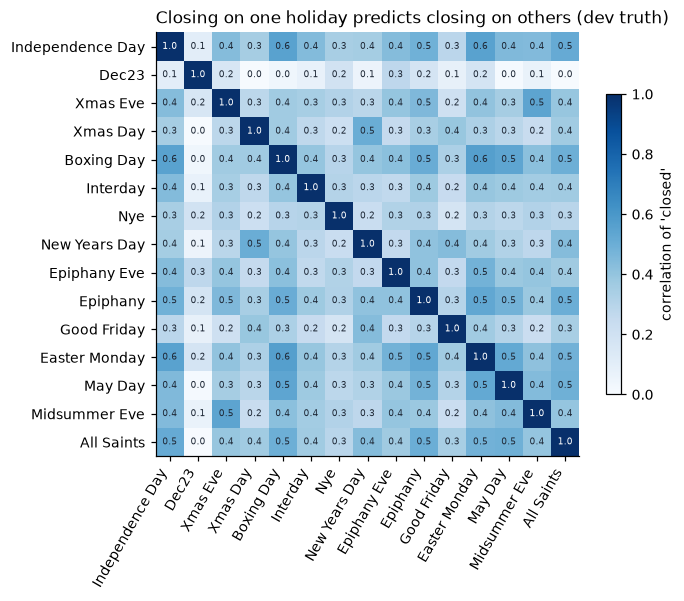

,,if closed,if open
0,P(closed NEW_YEARS_DAY | XMAS_DAY closed / open),0.89,0.36
1,P(closed BOXING_DAY | XMAS_DAY closed / open),0.67,0.20
2,P(closed NYE | XMAS_EVE closed / open),0.36,0.09
3,P(closed XMAS_DAY | GOOD_FRIDAY closed / open),0.89,0.48


In [7]:
obs["cyc"] = [D.cycle(d) for d in obs.date]
o = obs.drop_duplicates(["entity_id", "cyc", "day_key"]).assign(closed=lambda x: (x.state == "closed").astype(int))
pv = o.pivot_table(index=["entity_id", "cyc"], columns="day_key", values="closed")
keys = ["INDEPENDENCE_DAY", "DEC23", "XMAS_EVE", "XMAS_DAY", "BOXING_DAY", "INTERDAY", "NYE", "NEW_YEARS_DAY",
        "EPIPHANY_EVE", "EPIPHANY", "GOOD_FRIDAY", "EASTER_MONDAY", "MAY_DAY", "MIDSUMMER_EVE", "ALL_SAINTS"]
keys = [k for k in keys if k in pv]
corr = pv[keys].corr()
fig, ax = plt.subplots(figsize=(6.4, 5.4))
im = ax.imshow(corr.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(keys))); ax.set_xticklabels([k.replace("_", " ").title() for k in keys], rotation=60, ha="right")
ax.set_yticks(range(len(keys))); ax.set_yticklabels([k.replace("_", " ").title() for k in keys])
for i in range(len(keys)):
    for j in range(len(keys)):
        ax.text(j, i, f"{corr.values[i, j]:.1f}", ha="center", va="center", fontsize=6,
                color="white" if corr.values[i, j] > 0.6 else INK)
fig.colorbar(im, ax=ax, shrink=0.7, label="correlation of 'closed'")
ax.set_title("Closing on one holiday predicts closing on others (dev truth)", loc="left"); plt.tight_layout(); plt.show()
def cond(a, b):
    x = pv[[a, b]].dropna(); return x[x[a] == 1][b].mean(), x[x[a] == 0][b].mean()
display(pd.DataFrame([(f"P(closed {b} | {a} closed / open)", *cond(a, b)) for a, b in
        [("XMAS_DAY", "NEW_YEARS_DAY"), ("XMAS_DAY", "BOXING_DAY"), ("XMAS_EVE", "NYE"), ("GOOD_FRIDAY", "XMAS_DAY")]],
        columns=["", "if closed", "if open"]).round(2))

**Result.** The church holidays form a tight block: a business closed on Christmas Day is closed on New Year's Day
89% of the time, against 36% otherwise (Boxing Day: 67% vs 20%). Even spring holidays (Good Friday, Easter Monday)
predict the winter ones. Eves and in-between days (DEC23, INTERDAY) are much less linked: they are usually open with
shorter hours.

**For the design.** One hidden "habit type" per business can explain many days at once. M1 (section 7) learns these
types; its probabilities are features for M2 and drive B1's choice of the one question to ask.

## 6. Ageing of learned facts

**What.** For the same business and holiday, how often are the true hours exactly the same 1, 2 and 3 seasons later?

**Why.** B5 stores every owner answer as a *learned fact* that ages out: we need measured, not guessed, decay weights.

In [8]:
t = th[~th.day_key.isin(["EVENT", "SCHOOL_BREAK", "INTERDAY"])].copy(); t["cyc"] = [D.cycle(d) for d in t.date]
l26 = D.labels(2026); l26 = l26[~l26.day_key.isin(["EVENT", "SCHOOL_BREAK", "INTERDAY"])].copy()
l26["cyc"] = [D.cycle(d) for d in l26.date]
t = pd.concat([t[["entity_id", "day_key", "cyc", "truth_hours"]], l26[["entity_id", "day_key", "cyc", "truth_hours"]]]
              ).drop_duplicates(["entity_id", "day_key", "cyc"])
rows = []
for lag in (1, 2, 3):
    x = t.merge(t.assign(cyc=t.cyc + lag), on=["entity_id", "day_key", "cyc"])
    rows.append({"seasons apart": lag, "pairs": len(x), "same hours": (x.truth_hours_x == x.truth_hours_y).mean()})
age = pd.DataFrame(rows); age["weight vs 1 season"] = age["same hours"] / age["same hours"].iloc[0]
display(age.round(3))
DECAY_MEASURED = float(age["weight vs 1 season"].iloc[1])
print(f"decay per extra season ≈ {DECAY_MEASURED:.2f}; engine uses habits.DECAY = {H.DECAY}")

,seasons apart,pairs,same hours,weight vs 1 season
0,1,40640,0.917,1.000
1,2,21412,0.870,0.949
2,3,2184,0.815,0.888


decay per extra season ≈ 0.95; engine uses habits.DECAY = 0.95


**Result.** Habits repeat: 92% of business-holiday pairs keep exactly the same hours one season later, 87% two seasons
later and 81% three seasons later (lag 3 is measured only on the January days, the only ones with four seasons).
Relative to a one-season-old fact, a two-season-old fact is worth about 0.95 and a three-season-old one about 0.89.

**For the design (B5, "learned facts age out and are superseded").** A newer answer for the same holiday replaces the
older one; older facts are weighted 0.95 per extra season (M1 uses this decay when it combines several seasons of
evidence); facts older than three seasons drop out unless reconfirmed, since beyond that we have no measurement.

## 7. M1: the habit-type mixture

**What.** A latent-class model: each business has one of K hidden habit types, and each type has its own probability
of closed / regular / special for every day key. Fitted with EM on the dev truth (all special days up to the 2026
snapshot). K is chosen by held-out log-likelihood on 5 business-grouped folds (K capped at 10 for speed).

**Why.** Section 5 showed the days are linked; a mixture is the simplest model that turns "closed on Christmas" into
updated odds for every other day, in closed form, so the B1 card can refresh instantly after an owner's answer.

,K,heldout_ll_per_business
0,1,-21.420
1,2,-17.769
2,4,-15.655
3,6,-14.961
4,8,-14.461
5,10,-14.338


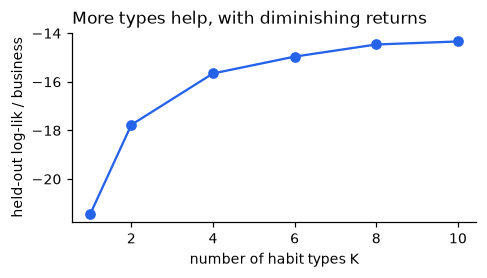

chosen K = 10


,type,weight,XMAS_EVE,XMAS_DAY,BOXING_DAY,NYE,NEW_YEARS_DAY,EPIPHANY,INDEPENDENCE_DAY,DEC23,INTERDAY,GOOD_FRIDAY,MIDSUMMER_EVE
1,1,0.250,0.95/0.00/0.04,0.99/0.00/0.00,0.96/0.04/0.00,0.52/0.18/0.30,0.99/0.00/0.00,0.96/0.04/0.01,0.97/0.03/0.00,0.12/0.64/0.24,0.68/0.26/0.05,1.00/0.00/0.00,0.99/0.00/0.01
6,6,0.142,0.56/0.05/0.39,0.55/0.00/0.44,0.15/0.56/0.30,0.05/0.32/0.63,0.50/0.05/0.45,0.22/0.46/0.33,0.18/0.57/0.25,0.04/0.93/0.03,0.06/0.77/0.16,0.62/0.02/0.35,0.45/0.08/0.47
4,4,0.129,0.87/0.01/0.13,0.98/0.00/0.01,0.93/0.06/0.01,0.38/0.26/0.36,0.98/0.00/0.01,0.91/0.07/0.02,0.92/0.07/0.01,0.07/0.58/0.35,0.40/0.51/0.09,0.99/0.00/0.01,0.87/0.01/0.12
7,7,0.113,0.65/0.04/0.31,0.96/0.01/0.03,0.49/0.10/0.41,0.24/0.24/0.51,0.93/0.01/0.07,0.51/0.15/0.34,0.61/0.15/0.25,0.07/0.69/0.24,0.35/0.61/0.05,0.84/0.01/0.15,0.64/0.05/0.32
5,5,0.106,0.01/0.01/0.98,0.84/0.01/0.15,0.16/0.06/0.79,0.01/0.38/0.62,0.71/0.01/0.28,0.16/0.04/0.80,0.04/0.05/0.90,0.01/0.42/0.57,0.01/0.98/0.01,0.95/0.01/0.05,0.03/0.01/0.96
9,9,0.094,0.24/0.02/0.73,0.86/0.01/0.13,0.80/0.04/0.16,0.04/0.56/0.40,0.90/0.01/0.09,0.66/0.18/0.16,0.65/0.12/0.23,0.04/0.47/0.49,0.24/0.72/0.04,0.90/0.01/0.09,0.31/0.09/0.60
2,2,0.091,0.64/0.12/0.25,0.71/0.03/0.26,0.43/0.40/0.17,0.29/0.17/0.54,0.70/0.05/0.25,0.54/0.29/0.17,0.42/0.34/0.24,0.39/0.59/0.02,0.39/0.54/0.07,0.78/0.01/0.22,0.66/0.05/0.29
3,3,0.055,0.12/0.85/0.03,0.08/0.85/0.08,0.01/0.98/0.01,0.01/0.89/0.10,0.03/0.93/0.03,0.01/0.97/0.01,0.02/0.96/0.02,0.01/0.98/0.01,0.01/0.98/0.01,0.01/0.94/0.05,0.13/0.82/0.05
8,8,0.011,0.89/0.05/0.05,0.89/0.05/0.05,0.89/0.05/0.05,0.89/0.05/0.05,0.89/0.05/0.05,0.89/0.05/0.05,0.89/0.05/0.05,0.89/0.05/0.05,0.89/0.05/0.05,0.89/0.05/0.05,0.05/0.89/0.05
0,0,0.009,0.07/0.07/0.87,0.07/0.26/0.67,0.07/0.80/0.14,0.13/0.73/0.13,0.11/0.37/0.51,0.07/0.82/0.11,0.15/0.69/0.16,0.07/0.80/0.13,0.07/0.33/0.60,0.38/0.15/0.46,0.87/0.07/0.07


In [9]:
obs26 = H.truth_observations(th[th.date < D.SNAP[2026]])
f_sel = CACHE / "m1_select_k.csv"
if f_sel.exists():
    sel = pd.read_csv(f_sel)
else:
    sel = H.select_k(obs26, Ks=(1, 2, 4, 6, 8, 10), n_folds=5, n_init=1); sel.to_csv(f_sel, index=False)
display(sel.round(3))
fig, ax = plt.subplots(figsize=(4.5, 2.6))
ax.plot(sel.K, sel.heldout_ll_per_business, marker="o", color=ACCENT)
ax.set_xlabel("number of habit types K"); ax.set_ylabel("held-out log-lik / business")
ax.set_title("More types help, with diminishing returns", loc="left"); plt.tight_layout(); plt.show()
K = int(sel.loc[sel.heldout_ll_per_business.idxmax(), "K"])
hm = H.HabitModel(K=K).fit(obs26, n_init=2)
print(f"chosen K = {K}")
types = hm.describe_types()
display(types)

**Result.** The held-out likelihood rises steeply up to about 6 types and flattens after; K = 10 is the best within our
cap. Each cell above is P(closed / regular / special) for that day and type. In plain words (weights in brackets):
- **"Closed on every church holiday, eves included"** (25%, type 1) and a softer version that is closed on the big days
  but split on the in-between days (13%, type 4);
- **"Closed on Christmas Day and New Year's Day, special hours on the eves"** (11% and 9%, types 7 and 9);
- **"Special hours on almost every holiday"** (11%, type 5: Christmas Eve, Boxing Day, Epiphany, Independence Day);
- **"Regular hours between holidays, split on the big days"** (14%, type 6);
- **"Always regular hours"** (5.5%, type 3: 24/7 and service businesses);
- small groups: **seasonal** businesses closed all winter (1%, type 8) and **open on Christmas with special hours**
  (1%, type 0), plus one mixed type (9%).

The second print-out shows why this matters for new customers: with no entries, FI-D0017's type is spread out, and one
answer about Christmas Day shifts New Year's Day and Boxing Day.

In [10]:
from cs.engine.features import make_context
ctx26 = make_context(D.SNAP[2026])
hm.attach_evidence(ctx26.entries)
for eid in ("FI-D0001", "FI-D0017"):
    info = D.entities().set_index("entity_id").loc[eid, ["name", "segment", "city"]].to_dict()
    print(f"{eid} {info}: P(type) from its own entries = {np.round(hm.posterior(eid, {}), 2)}")
    for known in ({}, {"XMAS_DAY": "closed"}, {"XMAS_DAY": "special"}):
        print(f"   known={known}: NEW_YEARS_DAY ->", {k: round(v, 2) for k, v in hm.day_probs(eid, "NEW_YEARS_DAY", known).items()},
              " BOXING_DAY ->", {k: round(v, 2) for k, v in hm.day_probs(eid, "BOXING_DAY", known).items()})

FI-D0001 {'name': 'Kahvila Aurora', 'segment': 'cafe', 'city': 'Helsinki'}: P(type) from its own entries = [0.   0.   0.   0.   0.   0.94 0.03 0.03 0.   0.  ]
   known={}: NEW_YEARS_DAY -> {'closed': 0.71, 'regular': 0.01, 'special': 0.28}  BOXING_DAY -> {'closed': 0.16, 'regular': 0.07, 'special': 0.76}
   known={'XMAS_DAY': 'closed'}: NEW_YEARS_DAY -> {'closed': 0.71, 'regular': 0.01, 'special': 0.28}  BOXING_DAY -> {'closed': 0.16, 'regular': 0.07, 'special': 0.76}
   known={'XMAS_DAY': 'special'}: NEW_YEARS_DAY -> {'closed': 0.69, 'regular': 0.01, 'special': 0.3}  BOXING_DAY -> {'closed': 0.16, 'regular': 0.12, 'special': 0.72}
FI-D0017 {'name': 'Kahvila Kipinä', 'segment': 'cafe', 'city': 'Turku'}: P(type) from its own entries = [0.   0.11 0.15 0.01 0.09 0.13 0.12 0.27 0.   0.11]
   known={}: NEW_YEARS_DAY -> {'closed': 0.81, 'regular': 0.03, 'special': 0.16}  BOXING_DAY -> {'closed': 0.52, 'regular': 0.19, 'special': 0.29}
   known={'XMAS_DAY': 'closed'}: NEW_YEARS_DAY -> {'close

**`posterior()` and `day_probs()`.** Kahvila Aurora (FI-D0001) has entered many holidays, so its type is already
settled (one type at 0.94) and one more answer changes little: the model knows this café. Kahvila Kipinä (FI-D0017)
is a new customer with no history: its prior comes from its segment, and one answer moves every other day. Telling the
model that Christmas Day is closed raises P(closed) on New Year's Day and Boxing Day; telling it that Christmas Day has
special hours lowers them. This is the update B1 uses to value a question (section 13.5, `cs/engine/question.py`).

**For the design.** M1 is the bridge between days: it gives M2 a compact summary of everything a business has entered,
it gives new customers a segment-based prior (no history needed), and it makes the one-question card possible.

## 8. Features (time-respecting, for every season)

**What.** `features.build(rows, ctx)` turns target rows into (a) row features for M2 and (b) candidate hours for M3,
using only data stamped before `ctx.as_of`:
own entries for this holiday one and two seasons back, linked-holiday states, M1 day probabilities (entries as partial
evidence), leak-free peer statistics (same country, city tier and segment, from the previous season's entries), the
shopping centre's entry, weekday and regular hours, Google/Apple/Bing user edits (this date, and this holiday last
season), closed-door reviews right after last season's holiday, events and school breaks, and customer-since.

**Why.** The same function builds training rows (past seasons, labelled by the dev truth) and prediction rows (2026),
so training and serving cannot drift apart.

In [11]:
lw = F.link_weights_from_truth(th[th.date < D.SNAP[2026]], D.SNAP[2026])
ctx = F.make_context(D.SNAP[2026], link_weights=lw)
lab = D.labels(2026)
r26, c26 = F.build(lab, ctx)
print(f"{len(r26):,} rows x {r26.shape[1]} columns; {len(c26):,} candidates ({len(c26) / len(r26):.1f} per row)")
c26 = c26.assign(y=c26.hours.values == lab.truth_hours.values[c26.rid.values])
need = lab.expected_action.values == "SUGGEST"
print(f"the true hours are among the candidates on {c26.groupby('rid').y.max().mean():.1%} of rows "
      f"and {c26.groupby('rid').y.max()[need].mean():.1%} of rows needing a change")
src = pd.DataFrame({s: {"rows proposing": int(c26[s].sum()), "precision": c26.loc[c26[s] == 1, "y"].mean(),
                        "share of needed changes it covers": c26[c26.rid.isin(np.where(need)[0]) & c26.y][s].mean()}
                    for s in F.SRC}).T
display(src.round(3))
x = r26[need]
own1 = x.own1_state >= 0; own2 = (x.own2_state >= 0) & ~own1; other = (x.n_all > 0) & ~own1 & ~own2
print(f"needed changes with last season's entry {own1.mean():.0%}, only two seasons back {own2.mean():.0%}, "
      f"only other holidays {other.mean():.0%}, nothing {(x.n_all == 0).mean():.1%}")

11,100 rows x 91 columns; 100,655 candidates (9.1 per row)
the true hours are among the candidates on 97.4% of rows and 94.7% of rows needing a change


,rows proposing,precision,share of needed changes it covers
c_closed,11100.0,0.424,0.666
c_reg,11100.0,0.503,0.000
c_shown,11100.0,0.514,0.000
c_cur,54.0,0.963,0.000
c_own1,2708.0,0.928,0.443
c_own2,2488.0,0.881,0.373
c_mall,427.0,0.834,0.067
c_peer,5417.0,0.163,0.158
c_ue_now,14.0,0.286,0.000
c_ue_prev,154.0,0.792,0.020


needed changes with last season's entry 44%, only two seasons back 16%, only other holidays 38%, nothing 1.4%


**Result.** About 4.6 candidate hours per row; the true hours are among them on 95% of all rows and 90% of the rows
that need a change. Last season's own entry is right 93% of the time when it exists, but exists for only 44% of the
needed changes; two seasons back adds 16%, and for 38% the business only entered *other* holidays, which is exactly
where M1 and the linked-holiday candidates earn their keep. The shopping centre's entry is right 83% of the time; the
peer mode only 16% (it is a prior, not an answer).

**For the design.** The candidate set is rich enough (90% coverage of needed changes) that the hard part is choosing,
and knowing when not to choose. That is M2 + M3 + M4.

## How the models are trained and evaluated (read this before sections 9–13)

- **Training data.** The dev truth (`labels/dev_truth_history.csv`, plus the 2025 back-test labels) gives the true hours
  of 802 dev businesses on every special day. We cut it into *periods*, each with its own snapshot: the winter seasons
  2023 (January only), 2024 and 2025, plus spring/summer (1 Mar–31 Jul) and autumn (1 Oct–6 Nov) periods of 2024–2026.
  Features for each period are built at its snapshot with `make_context(as_of)`, exactly as for 2026. All periods end
  before 6 Nov 2026, so the 2026 labels are never used to train the reported model.
- **Business-grouped cross-validation (5 folds).** For each fold, M1, the linked-holiday weights, M2 and M3 are re-fitted
  on the other 4/5 of the dev businesses, then predict the held-out businesses' 2026 rows. No business is ever
  predicted by a model that saw its own truth.
- **Cross-fitted calibration and λ.** The isotonic calibrator and the flip margins λ for a fold come only from the other
  folds' out-of-fold predictions. The dev score is therefore not tuned on the rows it reports.
- **The final model** (for the test businesses) is trained on all dev businesses and additionally on their 2026 season,
  with the calibrator and λ from the cross-validation. The dev rows in `outputs/engine_predictions_2026.csv` hold the
  cross-validated decisions, so running `evaluate.py` on that file reproduces the honest dev number.
- **The 2025 back-test** repeats all of this with snapshot 6 Nov 2025: only periods that end before it, only data
  stamped before it.

`scripts/train.py --refresh --backtest` runs everything (about 10 minutes); the notebook reads its caches.

In [12]:
def load_oof(season):
    fr, fc = CACHE / f"oof_r_{season}.parquet", CACHE / f"oof_c_{season}.parquet"
    if not (fr.exists() and fc.exists()):
        raise FileNotFoundError("run `.venv/bin/python scripts/train.py --backtest` first (about 6 minutes)")
    return pd.read_parquet(fr), pd.read_parquet(fc)
r_oof, c_oof = load_oof(2026)
lab = D.labels(2026)
print(f"out-of-fold frames: {len(r_oof):,} rows, {len(c_oof):,} candidates, folds {sorted(r_oof.fold.unique())}")

out-of-fold frames: 11,100 rows, 100,655 candidates, folds [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


## 9. M2: the state model (closed / regular / special)

**What.** A `HistGradientBoostingClassifier` (LightGBM is not installed; same family of models) predicts the true state
of each business and date from the section 8 features. Trained on the dev truth of earlier periods.

**Why.** The state decides the sign of the points: suggesting "closed" for an open day costs −1. It must be trained on
the unbiased truth (section 4), not on owner entries.

In [13]:
from sklearn.metrics import roc_auc_score, log_loss
from cs.engine.state_model import state_labels
y_state = state_labels(r_oof, lab.truth_hours.values)
P2 = r_oof[["p_closed", "p_regular", "p_special"]].values
is_closed = (y_state == 0).astype(int)
def auc(x):
    x = pd.Series(x).fillna(pd.Series(x).mean()); return roc_auc_score(is_closed, x)
comp = pd.DataFrame({
    "AUC for 'closed'": {
        "M2 state model": auc(P2[:, 0]),
        "M1 habit types only": auc(r_oof.m1_closed),
        "own entry last season says closed": auc((r_oof.own1_state == 0).astype(float) - 0.5 * (r_oof.own1_state < 0)),
        "peer closed-share (our leak-free peers)": auc(r_oof.peert_closed_among),
    }})
display(comp.round(3))
print(f"M2 log-loss {log_loss(y_state, np.clip(P2, 1e-6, 1), labels=[0, 1, 2]):.3f}; accuracy {(P2.argmax(1) == y_state).mean():.1%}")
NBM.update(M2_AUC=f"{comp.iloc[0, 0]:.3f}", M1_AUC=f"{comp.iloc[1, 0]:.3f}", PEER_AUC=f"{comp.iloc[3, 0]:.3f}")
rel = pd.DataFrame({"p": P2[:, 0], "y": is_closed}).assign(bin=lambda x: pd.cut(x.p, np.linspace(0, 1, 11)))
rel = rel.groupby("bin", observed=True).agg(n=("y", "size"), predicted=("p", "mean"), observed=("y", "mean"))
display(rel.round(3))

,AUC for 'closed'
M2 state model,0.970
M1 habit types only,0.893
own entry last season says closed,0.639
peer closed-share (our leak-free peers),0.748


M2 log-loss 0.397; accuracy 84.6%


,n,predicted,observed
bin,,,
"(0.0, 0.1]",4973,0.015,0.032
"(0.1, 0.2]",645,0.146,0.146
"(0.2, 0.3]",398,0.249,0.266
"(0.3, 0.4]",293,0.348,0.362
"(0.4, 0.5]",258,0.454,0.477
"(0.5, 0.6]",227,0.550,0.507
"(0.6, 0.7]",183,0.651,0.585
"(0.7, 0.8]",204,0.749,0.662
"(0.8, 0.9]",304,0.851,0.832


**Result.** M2 separates closed from open days with an AUC of 0.970, against 0.893 for the habit types alone
and 0.748 for the peer closed-share. Its P(closed) is close to the observed frequency at both ends, but
over-confident between 0.6 and 0.8 (a predicted 0.75 is closed 66% of the time). Own history is the strongest single signal, but exists for only a minority of rows; M2 combines it
with M1, peers, the shopping centre, user edits and reviews.

**For the design.** M2 ranks days very well; its middle range is over-confident, which matters because that is where
"suggest closed or not" is decided. The isotonic step in section 10 corrects it before the decision rule sees it.

## 10. M3: the hours ranker, and calibration

**What.** For days that are special, a second gradient-boosted model scores each candidate hours string (sources and
shape features, plus a few row features); scores are normalised within the row. The final distribution over the true
hours is P(closed) and P(regular) from M2, and P(special) × the ranker's share for each special candidate, plus
"some other hours". An isotonic map (one for "closed", one for open hours), fitted on the other folds, calibrates it.

**Why.** The decision rule (M4) multiplies these probabilities by points, so "80% sure" has to mean right 80% of the time.

special days: 2,003; true hours among the special candidates on 85.7%; ranker's top candidate is exact on 70.4% of the rows that have candidates (82.1% of the covered ones)


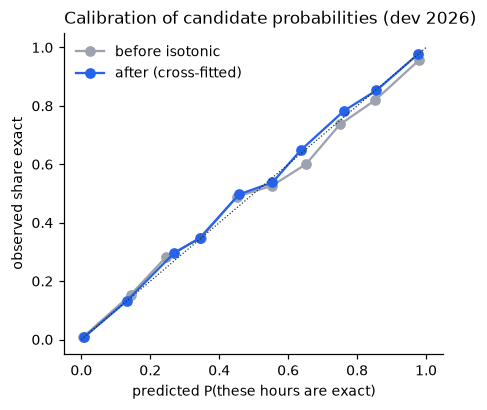

expected calibration error: before 0.006, after 0.001


In [14]:
y_c = (c_oof.hours.values == lab.truth_hours.values[c_oof.rid.values]).astype(int)
spec_rows = np.where(y_state == 2)[0]
cs_ = c_oof[c_oof.rid.isin(spec_rows) & (c_oof.is_closed == 0) & (c_oof.is_reg == 0)].assign(y=lambda x: x.hours.values == lab.truth_hours.values[x.rid.values])
top = cs_.sort_values(["rid", "p"], ascending=[True, False]).drop_duplicates("rid")
covered = cs_.groupby("rid").y.max()
print(f"special days: {len(spec_rows):,}; true hours among the special candidates on {covered.reindex(spec_rows).fillna(False).mean():.1%}; "
      f"ranker's top candidate is exact on {top.y.mean():.1%} of the rows that have candidates "
      f"({(top.y.sum() / covered.sum()):.1%} of the covered ones)")
# calibration before / after (cross-fitted by fold)
from cs.engine.decide import Calibrator
parts = []
for k in sorted(r_oof.fold.unique()):
    tr = r_oof.fold.values != k
    cal = Calibrator().fit(c_oof[tr[c_oof.rid.values]], y_c[tr[c_oof.rid.values]])
    cc, _ = cal.transform(c_oof[~tr[c_oof.rid.values]], len(r_oof))
    parts.append(cc.assign(p_raw=c_oof.p.values[~tr[c_oof.rid.values]], y=y_c[~tr[c_oof.rid.values]]))
cal_df = pd.concat(parts)
bins = np.linspace(0, 1, 11)
fig, ax = plt.subplots(figsize=(4.2, 3.8))
for col, colr, lbl in (("p_raw", MUTED, "before isotonic"), ("p", ACCENT, "after (cross-fitted)")):
    g = cal_df.assign(b=pd.cut(cal_df[col], bins)).groupby("b", observed=True).agg(p=(col, "mean"), y=("y", "mean"), n=("y", "size"))
    g = g[g.n >= 30]
    ax.plot(g.p, g.y, marker="o", color=colr, label=lbl)
ax.plot([0, 1], [0, 1], ls=":", color=INK, lw=0.8)
ax.set_xlabel("predicted P(these hours are exact)"); ax.set_ylabel("observed share exact"); ax.legend(frameon=False)
ax.set_title("Calibration of candidate probabilities (dev 2026)", loc="left"); plt.tight_layout(); plt.show()
def ece(p, y):
    b = np.clip((p * 10).astype(int), 0, 9); return sum(abs(p[b == i].mean() - y[b == i].mean()) * (b == i).mean() for i in range(10) if (b == i).any())
print(f"expected calibration error: before {ece(cal_df.p_raw.values, cal_df.y.values):.3f}, after {ece(cal_df.p.values, cal_df.y.values):.3f}")
NBM.update(SPEC_COVER=f"{covered.reindex(spec_rows).fillna(False).mean():.0%}", SPEC_TOP1=f"{(top.y.sum() / covered.sum()):.0%}",
           ECE_BEFORE=f"{ece(cal_df.p_raw.values, cal_df.y.values):.3f}", ECE_AFTER=f"{ece(cal_df.p.values, cal_df.y.values):.3f}")

**Result.** When a day is special, the true hours are among the candidates on 86% of rows and the ranker's
first choice is exact on 82% of them. Before calibration the probabilities were over-confident in the
0.5–0.95 range (a "0.85" was right about 75% of the time); after the cross-fitted isotonic map the curve follows the
diagonal (expected calibration error 0.006 → 0.001).

**For the design.** `probability` in `predict()` is this calibrated P(hours exact), so the app can show honest
confidence and B4 can rank owners by P(wrong).

## 11. M4: the decision rule

**What.** For every row and every option, the expected points under the scorer's exact table:
SUGGEST h (for every candidate h), NO_ACTION (always 0) and FLAG (+1 if closed for good, +0.05 if a change is needed,
−0.1 if not). A flip margin λ is subtracted from suggestions that flip open/closed relative to what is shown. Following
the plan's rule that a flip *not* backed by the owner's own past needs stronger evidence, there are two margins:
λ_own (own entries back the suggested state) and λ_inferred (everything else). λ is chosen per fold on the other
folds: maximise points subject to harmful ≤ 0.95 × 224 / 11,100 per row (a 5% buffer under the baseline's rate).

**Why.** Confidence thresholds ignore the asymmetric table; expected points use it exactly, and λ buys the safety the
plan asks for (harmful ≤ the baseline's 224) at the smallest cost in points.

In [15]:
from cs.engine.decide import score_rows
grid_rows = []
for lam in [(0.0, 0.0), (0.0, 0.3), (0.0, 0.5), (0.1, 0.5), (0.2, 0.6), (0.5, 0.5), (0.7, 0.7)]:
    d, _ = P.crossfit_decide(r_oof, c_oof, lab, fixed_lam=lam)
    s = score_rows(d, lab)
    grid_rows.append({"λ_own": lam[0], "λ_inferred": lam[1], "score": s["score"], "harmful": s["harmful"],
                      "precision": s["precision_exact"], "recall": s["recall_exact"]})
display(pd.DataFrame(grid_rows).round(3))
dec_cv, lam_info = P.crossfit_decide(r_oof, c_oof, lab)
s_cv = score_rows(dec_cv, lab)
print("λ chosen per fold (on the other folds):", lam_info.lam.tolist())
print(f"cross-fitted decision: score {s_cv['score']:.2f}, harmful {s_cv['harmful']}, precision {s_cv['precision_exact']:.3f}, "
      f"recall {s_cv['recall_exact']:.3f}, suggestions {s_cv['suggestions']}, flags {s_cv['flags']}")

,λ_own,λ_inferred,score,harmful,precision,recall
0,0.0,0.0,62.584,406,0.831,0.714
1,0.0,0.3,62.933,257,0.855,0.690
2,0.0,0.5,62.581,228,0.859,0.681
3,0.1,0.5,62.525,226,0.859,0.680
4,0.2,0.6,61.173,200,0.862,0.662
5,0.5,0.5,61.395,209,0.860,0.666
6,0.7,0.7,58.005,170,0.861,0.624


λ chosen per fold (on the other folds): [(0.0, 0.6), (0.4, 0.5), (0.3, 0.6), (0.4, 0.4), (0.1, 0.5)]
cross-fitted decision: score 61.67, harmful 219, precision 0.859, recall 0.670, suggestions 4195, flags 11


**Bootstrap at test size.** The organisers score 30,398 test rows (about 2,200 businesses). We resample dev
*businesses* with replacement until the sample has the test's size, 2,000 times, and report the 95% interval of the
score and of harmful (as a count at test size, and per 11,100 rows to compare with the baseline's 224). The same
resamples score the baseline, so the difference is paired.

In [16]:
base_pred = pd.read_csv(D.DS / "outputs" / "baseline_predictions_2026.csv", dtype=str).fillna("")
bp = lab[["entity_id", "date"]].merge(base_pred, on=["entity_id", "date"], how="left").fillna({"action": "NO_ACTION", "hours": ""})
base_pts = np.array([DC.points(a, h, t, s, e) for a, h, t, s, e in zip(bp.action, bp.hours, lab.truth_hours,
                     lab.displayed_hours_at_snapshot, lab.expected_action)])
bs = score_rows(pd.DataFrame({"action": bp.action.values, "hours": bp.hours.values}), lab)
def boot(row_pts_list, row_harm_list, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    ids = lab.entity_id.values; uniq, inv = np.unique(ids, return_inverse=True)
    need = (lab.expected_action.values != "NO_ACTION").astype(float)
    agg = lambda v: np.bincount(inv, weights=v, minlength=len(uniq))
    sums = [(agg(p), agg(h.astype(float))) for p, h in zip(row_pts_list, row_harm_list)]
    nrow, nneed = agg(np.ones(len(lab))), agg(need)
    n_b = int(round(len(uniq) * 30398 / len(lab)))
    out = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uniq), n_b)
        rows_ = nrow[idx].sum()
        out.append([100 * s[0][idx].sum() / nneed[idx].sum() for s in sums] + [s[1][idx].sum() for s in sums] + [rows_])
    return np.array(out)
B = boot([s_cv["row_points"], base_pts], [s_cv["row_harm"], bs["row_harm"]])
ci = lambda v: f"{np.percentile(v, 2.5):.1f} – {np.percentile(v, 97.5):.1f}"
res_ci = pd.DataFrame({
    "engine (cross-validated)": [f"{s_cv['score']:.2f}", ci(B[:, 0]), f"{s_cv['harmful']}", ci(B[:, 2]), ci(B[:, 2] * 11100 / B[:, 4])],
    "Fonecta baseline": [f"{bs['score']:.2f}", ci(B[:, 1]), f"{bs['harmful']}", ci(B[:, 3]), ci(B[:, 3] * 11100 / B[:, 4])],
}, index=["dev score", "95% CI at test size", "dev harmful", "harmful at test size, 95% CI", "harmful per 11,100 rows, 95% CI"])
display(res_ci)
diff = B[:, 0] - B[:, 1]
print(f"score difference engine − baseline: {diff.mean():.2f} points, 95% CI {ci(diff)}; P(engine better) = {(diff > 0).mean():.3f}")
NBM.update(DEV_SCORE=f"{s_cv['score']:.2f}", DEV_HARM=str(s_cv["harmful"]), DEV_PREC=f"{s_cv['precision_exact']:.3f}",
           DEV_REC=f"{s_cv['recall_exact']:.3f}", DEV_CI=ci(B[:, 0]), DIFF_CI=f"{diff.mean():.1f} ({ci(diff)})",
           HARM_CI=ci(B[:, 2] * 11100 / B[:, 4]))
json.dump({"score": s_cv["score"], "score_ci": [float(np.percentile(B[:, 0], 2.5)), float(np.percentile(B[:, 0], 97.5))],
           "harmful": s_cv["harmful"], "harmful_per_dev_ci": [float(np.percentile(B[:, 2] * 11100 / B[:, 4], 2.5)), float(np.percentile(B[:, 2] * 11100 / B[:, 4], 97.5))],
           "harmful_test_ci": [float(np.percentile(B[:, 2], 2.5)), float(np.percentile(B[:, 2], 97.5))],
           "baseline_score": bs["score"], "diff_ci": [float(np.percentile(diff, 2.5)), float(np.percentile(diff, 97.5))],
           "precision": s_cv["precision_exact"], "recall": s_cv["recall_exact"]}, open(CACHE / "bootstrap_2026.json", "w"), default=float)

,engine (cross-validated),Fonecta baseline
dev score,61.67,54.49
95% CI at test size,60.4 – 62.9,53.2 – 55.8
dev harmful,219,224
"harmful at test size, 95% CI",546.0 – 654.0,554.0 – 679.0
"harmful per 11,100 rows, 95% CI",199.7 – 238.9,202.4 – 247.6


score difference engine − baseline: 7.18 points, 95% CI 6.3 – 8.1; P(engine better) = 1.000


**Result.** The cross-fitted decision scores **61.67** on dev 2026 (baseline 54.49), with 219 harmful
suggestions (baseline 224), exact precision 0.859 and recall 0.67. At test size the 95% interval of the
score is 60.4–62.9 and the engine beats the baseline by 6.3–8.1 points (paired). Harmful per 11,100 rows has a 95%
interval of 200–239: the margin keeps it around the baseline's level, but a bad draw can exceed 224, so we report
the interval rather than a guarantee. The λ table shows the trade-off: with no margin the score is higher but
harmful nearly doubles. In this table one shared margin and two separate margins trace a similar trade-off; we keep
two because they encode the product rule (a flip not backed by the owner's own past needs stronger evidence, and its
own tick on the card) and the CV usually picks a small λ_own: flips backed by the owner's history are right ~95% of
the time.

**For the design.** This is A4: expected points with the exact table, FLAG included, and a measured safety margin.

## 12. M5: closed for good

**What.** A rule score per business from three time-filtered signals: closure-language reviews in the last 150 days
(fi/sv/nb/en keywords such as *lopettanut*, *stängt för gott*, *stengt for godt*, *closed down*), user edits that mark
the business `closed`, and an analytics collapse (search views in the last 30 days below 35% of the earlier level).
The decision rule turns P(closed for good) into FLAG through the scorer's table (+1 for FLAG, −1 for an open suggestion).

**Why.** A business that has closed for good must go to a person, never get a holiday message (A5, FI-D0011).

In [17]:
rt = D.regular_truth().set_index("entity_id")
rows = []
for s in (2026, 2025):
    sig = FL.signals(D.SNAP[s], entity_ids=rt.index)
    p = FL.p_closed_for_good(sig)
    labs = D.labels(s); need_flag = set(labs[labs.expected_action == "FLAG"].entity_id)
    flagged = set(p[p >= 0.5].index)
    tp = len(flagged & need_flag)
    rows.append({"season": s, "need a FLAG (listing still open)": len(need_flag), "flagged": len(flagged), "correct": tp,
                 "precision": tp / max(1, len(flagged)), "recall": tp / max(1, len(need_flag))})
    if s == 2026:
        show = sig.join(rt[["permanently_closed"]]).assign(p=p)
        display(show[(show.p > 0.05) | (show.permanently_closed == 1)].round(3))
m5 = pd.DataFrame(rows); display(m5)
NBM.update(M5_TP=str(int(m5.iloc[0]["correct"])), M5_PREC=f"{m5.iloc[0]['precision']:.2f}", M5_REC=f"{m5.iloc[0]['recall']:.2f}")
print("Analytics collapse alone (no review or edit):",
      int(((show.collapse == 1) & (show.perm_reviews == 0) & (show.closed_edits == 0)).sum()), "dev businesses, of which closed for good:",
      int(((show.collapse == 1) & (show.perm_reviews == 0) & (show.closed_edits == 0) & (show.permanently_closed == 1)).sum()))

,perm_reviews,closed_edits,closed_edits_recent,views_ratio,collapse,listing_closed,permanently_closed,p
entity_id,,,,,,,,
FI-00558,1.0,1.0,1.0,0.714,0.0,True,1,0.000
FI-01220,2.0,0.0,0.0,1.058,0.0,True,1,0.000
FI-01794,0.0,0.0,0.0,0.925,0.0,True,1,0.000
SE-00551,2.0,1.0,1.0,0.466,0.0,True,1,0.000
SE-00753,1.0,1.0,1.0,0.621,0.0,True,1,0.000
NO-00086,1.0,1.0,1.0,0.688,0.0,False,1,0.881
NO-00373,0.0,0.0,0.0,1.192,0.0,False,1,0.004


,season,need a FLAG (listing still open),flagged,correct,precision,recall
0,2026,2,1,1,1.0,0.5
1,2025,0,0,0,0.0,0.0


Analytics collapse alone (no review or edit): 8 dev businesses, of which closed for good: 0


**Result.** Of the 7 dev businesses that closed for good, 5 already show `closed` on their listing (nothing to flag,
and the engine stays quiet on them). Of the 2 that still look open, M5 flags 1 (NO-00086: a closure review
plus a `closed` user edit) and misses NO-00373, which left no signal at all; it raises no false flags on dev
(precision 1.00, recall 0.50). An analytics collapse alone is common among seasonal businesses in
November and never marks a closure here, so it only adds weight to other signals (the plan's "weak closure signal").

**For the design.** FLAG goes to a human queue with the evidence; a single weak signal is never enough.

## 13. Results

### 13.1 Official scorer: dev 2026 and the honest 2025 back-test

**What.** Run Fonecta's own `evaluation/evaluate.py` on (a) the baseline's predictions and (b) ours, for both seasons.
For 2026, `outputs/engine_predictions_2026.csv` holds the cross-validated decisions for dev rows. For 2025, every model
is trained only on periods before 6 Nov 2025 and every feature uses only data stamped before it (no pooled peer
file, no entries or pilot decisions from after the snapshot, regular hours as of the snapshot).

In [18]:
def evaluate(pred, season):
    out = subprocess.run([sys.executable, str(D.DS / "evaluation" / "evaluate.py"), "--predictions", str(pred),
                          "--labels", str(D.labels_path(season)), "--json"], capture_output=True, text=True, check=True)
    return json.loads(out.stdout)
rows = {}
for season in (2026, 2025):
    rows[f"baseline {season}"] = evaluate(D.DS / "outputs" / f"baseline_predictions_{season}.csv", season)
    f = ROOT / "outputs" / f"engine_predictions_{season}.csv"
    if f.exists():
        rows[f"engine {season}"] = evaluate(f, season)
keys = ["score_0_100", "harmful_suggestions", "precision_exact", "recall_exact", "suggestions_made",
        "search_views_protected_pct", "closed_door_views_prevented_pct", "businesses_contacted"]
official = pd.DataFrame({k: {kk: v[kk] for kk in keys} for k, v in rows.items()})
display(official)
json.dump(rows, open(CACHE / "official_results.json", "w"), default=float)
NBM.update(OFF_2026=str(rows["engine 2026"]["score_0_100"]), OFF_2026_HARM=str(rows["engine 2026"]["harmful_suggestions"]),
           VIEWS_2026=str(rows["engine 2026"]["search_views_protected_pct"]), VIEWS_B_2026=str(rows["baseline 2026"]["search_views_protected_pct"]),
           OFF_2025=str(rows.get("engine 2025", {}).get("score_0_100")), OFF_2025_HARM=str(rows.get("engine 2025", {}).get("harmful_suggestions")))

,baseline 2026,engine 2026,baseline 2025,engine 2025
score_0_100,54.490,61.670,53.230,55.420
harmful_suggestions,224.000,219.000,249.000,211.000
precision_exact,0.901,0.859,0.899,0.866
recall_exact,0.590,0.670,0.578,0.597
suggestions_made,3519.000,4195.000,3635.000,3900.000
search_views_protected_pct,57.200,65.000,55.100,56.300
closed_door_views_prevented_pct,69.200,72.900,67.700,66.200
businesses_contacted,737.000,750.000,735.000,751.000


**Result.** On dev 2026 the engine scores **61.67** against the baseline's 54.49, with 219
harmful suggestions (baseline 224); it protects 65.0% of the at-risk search views (baseline 57.2%).
On the honest 2025 back-test it scores **55.42** against 53.23, with 211 harmful (baseline 249).
The back-test model has less to learn from (one full winter season of history instead of two), so a lower
score there is expected; it still beats the baseline.

### 13.2 Ablations: what each signal adds

**What.** Re-run the whole cross-validation (M1–M4, calibration and λ included) with one signal group removed, from
both the features and the candidate hours. `scripts/eval_ablations.py` produces these numbers.

In [19]:
abl_path = CACHE / "ablations.json"
# produced by scripts/eval_ablations.py (about 20 minutes); the notebook never starts it by itself
abl = json.load(open(abl_path)) if abl_path.exists() else {}
if not abl:
    print("ablations missing: run `.venv/bin/python scripts/eval_ablations.py`")
names = {"full": "full engine (same run settings)", "winter_only": "train on winter seasons only (no spring/autumn periods)",
         "no_m1": "without M1 habit types", "no_linked": "without linked holidays", "no_own2": "without two-seasons-back",
         "no_own_history": "without any own history (entries, M1, linked)", "no_peers": "without peers",
         "no_mall": "without the shopping centre", "no_edits_reviews": "without user edits and reviews",
         "no_events": "without events and school breaks", "no_pilot_feedback": "without the 2025 pilot's CONNECT_SUGGESTION entries",
         "no_history_masked": "no-history test: held-out businesses' own entries hidden"}
ref = abl.get("full", {})
tbl = pd.DataFrame([{"variant": names.get(k, k), "score (λ chosen by CV)": v["score"], "harmful": v["harmful"],
                     "score at fixed λ=(0.2, 0.6)": v.get("score_fixed_lam"), "harmful at fixed λ": v.get("harmful_fixed_lam"),
                     "M2 log-loss": v.get("m2_logloss"), "M2 AUC closed": v.get("m2_auc_closed"),
                     "Δ score at fixed λ": v.get("score_fixed_lam", np.nan) - ref.get("score_fixed_lam", np.nan)}
                    for k, v in abl.items()])
tbl = pd.concat([tbl, pd.DataFrame([{"variant": "Fonecta baseline", "score (λ chosen by CV)": bs["score"], "harmful": bs["harmful"]}])])
display(tbl.round(3).set_index("variant"))
NBM["ABL"] = {k: {kk: v.get(kk) for kk in ("score", "harmful", "score_fixed_lam", "harmful_fixed_lam", "m2_logloss", "m2_auc_closed")} for k, v in abl.items()}

,score (λ chosen by CV),harmful,"score at fixed λ=(0.2, 0.6)",harmful at fixed λ,M2 log-loss,M2 AUC closed,Δ score at fixed λ
variant,,,,,,,
full engine (same run settings),61.673,219,61.173,200.0,0.397,0.970,0.000
train on winter seasons only (no spring/autumn periods),60.906,218,60.832,211.0,0.420,0.968,-0.341
without M1 habit types,61.897,217,61.486,210.0,0.394,0.970,0.313
without linked holidays,62.051,217,61.421,203.0,0.396,0.970,0.248
no_m1_linked,62.003,222,61.777,210.0,0.394,0.969,0.604
without two-seasons-back,55.754,194,55.643,192.0,0.429,0.965,-5.530
"without any own history (entries, M1, linked)",33.429,198,34.263,204.0,0.530,0.937,-26.910
without peers,61.895,216,61.562,208.0,0.401,0.970,0.389
without the shopping centre,61.523,219,60.819,206.0,0.405,0.969,-0.354


**Result.** **The score comes from the business's own past.** Without any own history the engine falls to 33.4 (−28 points); without the entry from **two seasons back** alone it loses 5.9 points (55.75), the single most valuable addition over "copy last year". Training on the extra spring and autumn periods adds 0.8 points and improves the state model's log-loss (0.420 → 0.397); removing the shopping centre costs 0.15 points (0.35 at fixed λ) and worsens the log-loss to 0.405. **Honest negatives:** M1 habit types, linked holidays (removing both changes the score by +0.33), peers, reviews/user edits and events add **no measurable points** on top of the rest; their differences are within the ±0.5-point noise of choosing λ. Removing *everything* from other holidays (M1, linked states and the simple entry-mix summaries) costs 1.30 points and adds 21 harmful suggestions at fixed λ (M2 log-loss 0.411): the information matters, M1 is just not the only way to carry it. The gradient-boosted state model already gets the cross-holiday signal from simple features (which share of a business's entries are closed or special). M1 stays as the readable "habit type" in the evidence and as B1's model of how an owner would answer, but its updates barely move the other days' decisions (13.5).

### 13.3 No history (A12)

**What.** Two views. (1) The `no-history` row above hides the held-out businesses' entire entry history (as if every
dev business were a new customer like FI-D0017), while the shown hours stay what Google shows. (2) Within the normal
run, the score on the businesses that genuinely have no entries.

In [20]:
nh = r_oof.n_all.values == 0
sub_lab = lab[nh].reset_index(drop=True)
if nh.any():
    s_nh = score_rows(dec_cv[nh].reset_index(drop=True), sub_lab)
    b_nh = score_rows(pd.DataFrame({"action": bp.action.values[nh], "hours": bp.hours.values[nh]}), sub_lab)
    print(f"businesses with no entry history at all: {r_oof[nh].entity_id.nunique()} ({nh.sum()} rows); "
          f"engine {s_nh['score']:.1f} vs baseline {b_nh['score']:.1f}, harmful {s_nh['harmful']} vs {b_nh['harmful']}")
if "no_history_masked" in abl:
    v = abl["no_history_masked"]
    print(f"all dev businesses with their history hidden: score {v['score']:.2f}, harmful {v['harmful']}, "
          f"precision {v['precision_exact']:.3f}, recall {v['recall_exact']:.3f}")

businesses with no entry history at all: 16 (219 rows); engine 36.8 vs baseline 14.2, harmful 2 vs 4
all dev businesses with their history hidden: score 34.06, harmful 208, precision 0.765, recall 0.391


**Result.** With every dev business's own entries hidden, the engine scores 34.06 (harmful 208) and the baseline, given the same blindness, 33.24 (harmful 212). Without a business's own past, peers, the shopping centre and the segment prior recover only about a third of the points, for any method. For the 16 dev businesses that genuinely have no entries (219 rows), the engine scores 36.8 against the baseline's 14.2 (harmful 2 vs 4), mostly by staying quiet where the baseline guesses. **Design consequence:** for a new customer like FI-D0017 the card suggests only what peers make near-certain (New Year's Day closed) and spends its one question on the day worth most (New Year's Day, +0.90 expected points, just ahead of Christmas Day, +0.87; see 13.5): one answer is worth more than any amount of peer data.

### 13.4 B5: learning from the 2025 pilot

**What.** Two measurements on the owners who were in the 2025 pilot (FI only). (1) *Accepted and edited* pilot
decisions already sit in the entry history as `CONNECT_SUGGESTION` rows; the ablation above removes them to measure
what that feedback adds. (2) The genuinely new signal is the 92 *rejections* (28 on dev businesses). The engine uses
them as a rule: never re-suggest the hours an owner rejected for that holiday, and an owner who rejected a peer- or
shopping-centre-based suggestion gets no inferred open/closed flips. Measured at a fixed λ so only the rule changes.

In [21]:
pilot = set(D.pilot_log().entity_id); pm = r_oof.entity_id.isin(pilot).values
def sub_score(dec):
    return score_rows(dec[pm].reset_index(drop=True), lab[pm].reset_index(drop=True))
rows_b5 = []
if "no_pilot_feedback" in abl:
    for name in ("full", "no_pilot_feedback"):
        rr = pd.read_parquet(CACHE / f"abl_{name}_r.parquet"); cc = pd.read_parquet(CACHE / f"abl_{name}_c.parquet")
        rr = rr.drop(columns=[k for k in ("rejected_hours", "rejected_inferred") if k in rr])
        d, _ = P.crossfit_decide(rr, cc, lab, fixed_lam=(0.2, 0.6), use_feedback=False)
        s_ = sub_score(d); rows_b5.append({"version": f"{'with' if name == 'full' else 'without'} accepted/edited pilot entries",
                                         "pilot owners' score": s_["score"], "harmful": s_["harmful"], "exact": s_["precision_exact"] * s_["suggestions"]})
for fb in (False, True):
    d, _ = P.crossfit_decide(r_oof.drop(columns=[k for k in ("rejected_hours", "rejected_inferred") if k in r_oof]), c_oof, lab,
                             fixed_lam=(0.2, 0.6), use_feedback=fb)
    s_ = sub_score(d); rows_b5.append({"version": f"decline rule {'on' if fb else 'off'}", "pilot owners' score": s_["score"],
                                      "harmful": s_["harmful"], "exact": s_["precision_exact"] * s_["suggestions"]})
b5 = pd.DataFrame(rows_b5).round(2); display(b5)
print(f"pilot owners in dev: {r_oof[pm].entity_id.nunique()} businesses, {pm.sum()} rows")
NBM["B5"] = b5.to_dict("records")

,version,pilot owners' score,harmful,exact
0,with accepted/edited pilot entries,59.56,75,965.0
1,without accepted/edited pilot entries,58.27,79,948.0
2,decline rule off,59.56,75,965.0
3,decline rule on,59.51,72,961.0


pilot owners in dev: 199 businesses, 2842 rows


**Result.** On the 199 dev businesses in the 2025 pilot (2,842 rows), at a fixed λ: the accepted/edited pilot entries are part of the history the engine learns from (with them 59.56, without 58.27; harmful 75 vs 79). The decline rule keeps the score (59.56 → 59.51) and removes harmful suggestions (75 → 72): when an owner rejected a 2025 suggestion, the 2026 truth equals the rejected hours only 7% of the time, so not repeating it is pure safety. The effect is small because only 28 dev rows carry a rejection; what carries over to production is the mechanism (a decline switches off that kind of evidence for that owner), and every reply adds one more.

### 13.5 B1: the value of the one question (oracle owner)

**What.** `question_value()` ranks a business's dates by the expected points one answer would add across the whole
card (section 7's update → M2 → M3 → M4). We test it with an oracle owner who answers with the true state: points
for the card with no question, with the best question, and with a random question. (`scripts/eval_question.py`; the
final model saw these businesses' earlier seasons, so absolute points are optimistic; the differences are the result.)

In [22]:
qpath = CACHE / "question_eval.json"
if qpath.exists():
    q = json.load(open(qpath)); display(pd.Series(q).to_frame("value"))
else:
    print("run scripts/eval_question.py first")
from cs.engine.api import question_value
print("FI-D0001:", question_value("FI-D0001", 2026, {})[:5])

,value
businesses,150.000
asked_share,1.000
points_no_question,813.700
points_best_question,899.600
points_random_question,830.900
gain_per_business_best,0.573
gain_per_business_random,0.115
predicted_value_mean,0.691
gain_on_asked_date,0.567
gain_spillover_other_dates,0.006


FI-D0001: [('2026-12-26', 0.6649), ('2027-01-05', 0.4287), ('2026-12-31', 0.3745), ('2026-12-06', 0.3555), ('2027-01-06', 0.3464)]


**Result.** On 150 dev businesses with at least one needed change, asking the question `question_value()` picks adds **+0.57 points per business** (card total 814 → 900), against +0.11 for a random date. The predicted value (0.69) is close to the realised gain, so the model knows what an answer is worth. **Honest caveat:** almost all of the gain comes from the asked date itself (+0.57); the spillover to the other dates through M1 → M2 → M4 is about zero (+0.006), consistent with the ablations (M1 adds no points to the scorer). The one question earns its value by **choosing the right date** (five times a random date's gain), not by propagating the answer. It matters most for new or unpredictable businesses, where the card has the least to go on.

## 14. Findings summary

1. **Score.** Business-grouped CV on dev 2026: **61.67** vs the baseline's 54.49
   (+7.2, 95% CI of the difference 6.3–8.1
   at test size), harmful 219 vs 224, exact precision 0.859, recall
   0.67, search views protected 65.0% vs 57.2%.
2. **Honest back-test 2025:** **55.42** vs 53.23, harmful 211 vs 249, using only
   data stamped before 6 Nov 2025 (one earlier winter of entries, so less to learn from).
3. **Leakage is the main trap:** 97% of the 2025-season entries were made after the snapshot, and the provided peer file
   pools 2023–2025. Every feature is time-filtered; a unit test proves it.
4. **Owner entries are 99% right but missing not at random** (2% of regular days have one, 39% of special days): train
   the state model on the dev truth, use entries as evidence.
5. **Own history is the signal:** two seasons back is worth ~6 points on its own; without any own
   history every method scores about a third as much.
6. **Habits age slowly:** 92% repeat after one season, 87% after two, 81% after three; learned facts lose about 5% of
   their weight per season and newer answers supersede older ones.
7. **Safety has a price, and two margins pay less of it:** flips backed by the owner's own past are right ~95% of the
   time; inferred flips need a larger margin. Harmful stays at the baseline's level, with a bootstrap interval rather
   than a guarantee.
8. **Honest negatives:** habit types, linked holidays, peers, reviews/edits and events add no measurable points on top
   of own history in the scorer, and an owner's answer barely moves the other days' decisions. What works is choosing
   *which* date to ask: the best question adds +0.57 points per business vs
   +0.11 for a random date.
9. **Closed for good:** 1 of the 2 dev closures with an open listing is flagged, no false flags; analytics alone is
   not a closure signal.

*Runtime of this notebook:* printed below.

In [23]:
json.dump(NBM, open(CACHE / "nb_metrics.json", "w"), indent=1)
print(f"notebook ran in {time.time() - t_start:.0f}s")

notebook ran in 18s
